In [ ]:

# Import required libraries

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


In [ ]:

# Cell 2: Upload the dataset

uploaded = files.upload()

csv_files = [name for name in uploaded if name.lower().endswith(".csv")]

if not csv_files:
    raise ValueError("Please upload a CSV file containing the SMS dataset.")

df_raw = pd.read_csv(csv_files[0], encoding="latin-1")

print("Original shape:", df_raw.shape)
print("Available columns:", df_raw.columns.tolist())

display(df_raw.head())


Saving spam_sms.csv to spam_sms.csv
Original shape: (5572, 2)
Available columns: ['v1', 'v2']


,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:

# Cell 3: Data cleaning and subset selection

# Change this value if your jury asks for a different dataset size.
DATASET_SIZE = 2000

# Automatically identify the label and message columns.
column_map = {str(c).strip().lower(): c for c in df_raw.columns}

label_candidates = ["v1", "label", "category", "target", "class"]
text_candidates = ["v2", "message", "text", "sms", "sms_text"]

label_col = next(
    (column_map[c] for c in label_candidates if c in column_map),
    None
)
text_col = next(
    (column_map[c] for c in text_candidates if c in column_map),
    None
)

if label_col is None or text_col is None:
    raise ValueError(
        "Could not identify the label/text columns. "
        "Inspect df_raw.columns and set label_col and text_col manually."
    )

df = df_raw[[label_col, text_col]].copy()
df.columns = ["label", "message"]

# Handle missing and invalid rows
df = df.dropna(subset=["label", "message"])
df["label"] = df["label"].astype(str).str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()
df = df[df["message"] != ""]
df = df[df["label"].isin(["ham", "spam"])]

# Remove duplicate messages
df = df.drop_duplicates(subset=["message"]).reset_index(drop=True)

# Encode ham = 0 and spam = 1
df["label_num"] = df["label"].map({"ham": 0, "spam": 1})

print("Clean dataset size:", len(df))
print("\nClass distribution before sampling:")
print(df["label"].value_counts())

# Keep the requested size, while preserving class proportions.
if DATASET_SIZE > len(df):
    print("Requested size exceeds available rows; using all rows.")
    DATASET_SIZE = len(df)

if DATASET_SIZE < 20:
    raise ValueError("Choose a larger dataset for meaningful train/test evaluation.")

df, _ = train_test_split(
    df,
    train_size=DATASET_SIZE,
    random_state=42,
    stratify=df["label_num"]
)

df = df.reset_index(drop=True)

print("\nFinal dataset shape:", df.shape)
print("\nFinal class distribution:")
print(df["label"].value_counts())
display(df.head())


Clean dataset size: 5158

Class distribution before sampling:
label
ham     4516
spam     642
Name: count, dtype: int64

Final dataset shape: (2000, 3)

Final class distribution:
label
ham     1751
spam     249
Name: count, dtype: int64


,label,message,label_num
0,ham,Aight ill get on fb in a couple minutes,0
1,ham,I havent add Ã_ yet right..,0
2,spam,As one of our registered subscribers u can ent...,1
3,ham,I think its far more than that but find out. C...,0
4,ham,Lara said she can loan me &lt;#&gt; .,0


Missing values:
label      0
message    0
dtype: int64

Message lengths:
count    2000.000000
mean       15.043500
std        10.663464
min         1.000000
25%         7.000000
50%        12.000000
75%        22.000000
max       125.000000
Name: message, dtype: float64


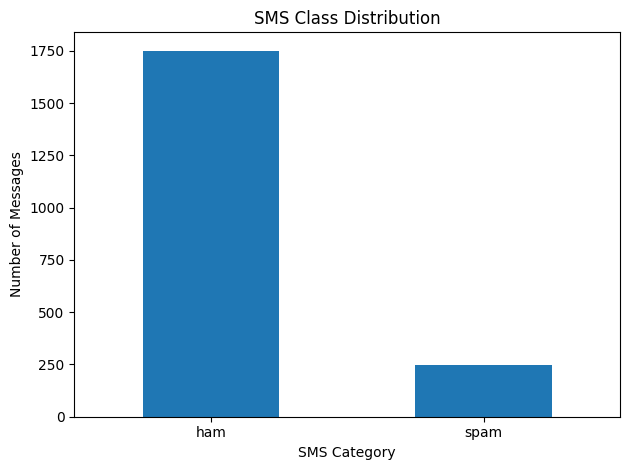

In [ ]:

# Cell 4: Explore the dataset

print("Missing values:")
print(df[["label", "message"]].isnull().sum())

print("\nMessage lengths:")
print(df["message"].str.split().str.len().describe())

df["label"].value_counts().reindex(["ham", "spam"]).plot(
    kind="bar", title="SMS Class Distribution", rot=0
)
plt.xlabel("SMS Category")
plt.ylabel("Number of Messages")
plt.tight_layout()
plt.show()


In [ ]:

# Cell 5: Split the data

SEED = 42

X = df["message"].astype(str).to_numpy()
y = df["label_num"].to_numpy()

# 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

# Split temporary data equally: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training messages:", len(X_train))
print("Validation messages:", len(X_val))
print("Testing messages:", len(X_test))


Training messages: 1400
Validation messages: 300
Testing messages: 300


In [ ]:

# Cell 6: Tokenize and pad messages

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Jury-adjustable parameters
VOCAB_SIZE = 5000
MAX_LEN = 50
OOV_TOKEN = "<OOV>"

# Fit tokenizer ONLY on training messages
tokenizer = Tokenizer(
    num_words=VOCAB_SIZE,
    oov_token=OOV_TOKEN,
    lower=True
)

tokenizer.fit_on_texts(X_train)

# Convert text into integer sequences
train_sequences = tokenizer.texts_to_sequences(X_train)
val_sequences = tokenizer.texts_to_sequences(X_val)
test_sequences = tokenizer.texts_to_sequences(X_test)

# Pad/truncate to equal length
X_train_pad = pad_sequences(
    train_sequences, maxlen=MAX_LEN,
    padding="post", truncating="post"
)

X_val_pad = pad_sequences(
    val_sequences, maxlen=MAX_LEN,
    padding="post", truncating="post"
)

X_test_pad = pad_sequences(
    test_sequences, maxlen=MAX_LEN,
    padding="post", truncating="post"
)

print("Vocabulary words:", min(VOCAB_SIZE, len(tokenizer.word_index) + 1))
print("Training array shape:", X_train_pad.shape)
print("Example message:", X_train[0])
print("Integer sequence:", train_sequences[0])
print("Padded sequence:", X_train_pad[0])


Vocabulary words: 4092
Training array shape: (1400, 50)
Example message: Po de :-):):-):-):-). No need job aha.
Integer sequence: [492, 305, 37, 83, 275, 493]
Padded sequence: [492 305  37  83 275 493   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0]


In [ ]:

# Cell 7: Build the LSTM model

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

EMBEDDING_DIM = 64
LSTM_UNITS = 64
DROPOUT_RATE = 0.30

model = Sequential([
    tf.keras.Input(shape=(MAX_LEN,)),

    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True
    ),

    LSTM(LSTM_UNITS),

    Dropout(DROPOUT_RATE),

    Dense(32, activation="relu"),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 64)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 355,137 (1.35 MB)

 Trainable params: 355,137 (1.35 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# Cell 8: Train the model

EPOCHS = 15
BATCH_SIZE = 32

# Compensate for class imbalance in the training set
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(label): float(weight)
    for label, weight in zip(classes, weights)
}

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

print("Training completed!")


Epoch 1/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 7s 58ms/step - accuracy: 0.5429 - loss: 0.5809 - val_accuracy: 0.9733 - val_loss: 0.3884 - learning_rate: 0.0010
Epoch 2/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - accuracy: 0.9729 - loss: 0.2105 - val_accuracy: 0.9633 - val_loss: 0.2103 - learning_rate: 0.0010
Epoch 3/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.9929 - loss: 0.0665 - val_accuracy: 0.9733 - val_loss: 0.1188 - learning_rate: 0.0010
Epoch 4/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.9964 - loss: 0.0280 - val_accuracy: 0.9767 - val_loss: 0.0819 - learning_rate: 0.0010
Epoch 5/15
43/44 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 1.0000 - loss: 0.0074
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 1.0000 - loss: 0.0072 - val_accuracy: 0.9767 - val_loss: 0.0913 - learning_rate: 0.0010
Epoch 6/15
43/44 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 1.0000 - loss: 0.0049
Epoch 6: R

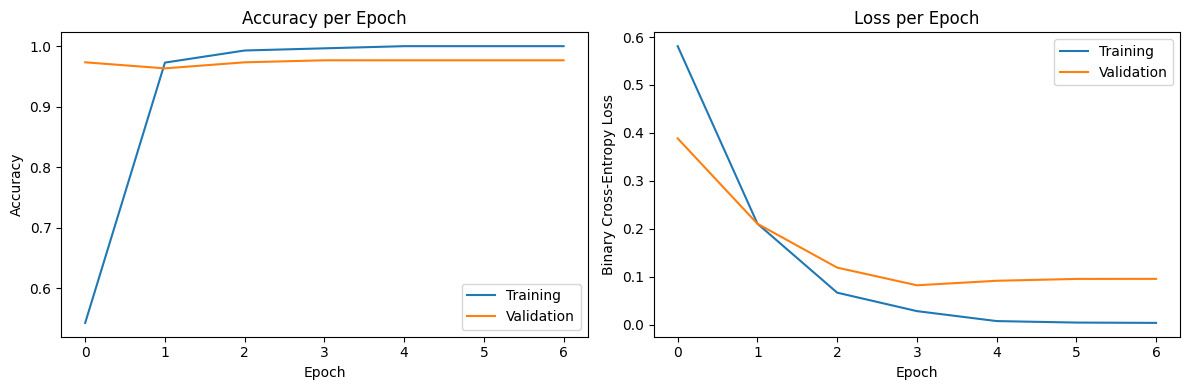

In [ ]:

# Cell 9: Visualize training and validation performance

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy per Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary Cross-Entropy Loss")
axes[1].legend()

plt.tight_layout()
plt.show()


In [ ]:

# Cell 10: Final test evaluation

THRESHOLD = 0.50

# Predict spam probabilities for test messages
test_probabilities = model.predict(X_test_pad, verbose=0).ravel()

# Convert probabilities into class predictions
y_pred = (test_probabilities >= THRESHOLD).astype(int)

accuracy = accuracy_score(y_test, y_pred)

# Positive class is spam (1)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("TEST RESULTS")
print("-" * 35)
print(f"Accuracy : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nDetailed classification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)


TEST RESULTS
-----------------------------------
Accuracy : 0.9767 (97.67%)
Precision: 0.8750
Recall   : 0.9459
F1-score : 0.9091

Detailed classification report:
              precision    recall  f1-score   support

         Ham       0.99      0.98      0.99       263
        Spam       0.88      0.95      0.91        37

    accuracy                           0.98       300
   macro avg       0.93      0.96      0.95       300
weighted avg       0.98      0.98      0.98       300



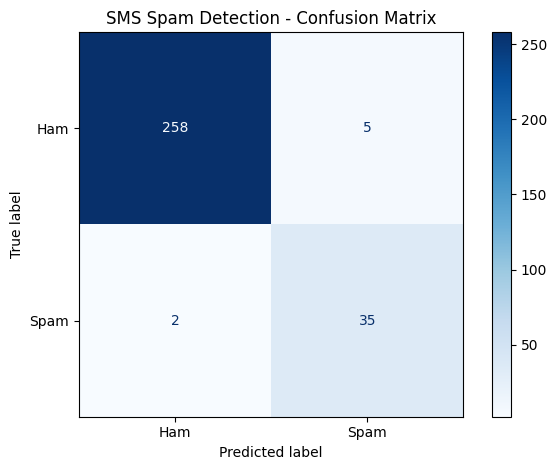

True Negatives (Ham correctly identified): 258
False Positives (Ham incorrectly flagged as spam): 5
False Negatives (Spam missed by model): 2
True Positives (Spam correctly detected): 35


In [ ]:

# Cell 11: Confusion matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

display_matrix.plot(cmap="Blues", values_format="d")
plt.title("SMS Spam Detection - Confusion Matrix")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negatives (Ham correctly identified):", tn)
print("False Positives (Ham incorrectly flagged as spam):", fp)
print("False Negatives (Spam missed by model):", fn)
print("True Positives (Spam correctly detected):", tp)


In [ ]:

# Cell 12: Predict new SMS messages

def predict_sms(message, threshold=THRESHOLD):
    if not isinstance(message, str) or not message.strip():
        raise ValueError("Please enter a non-empty SMS message.")

    # Use the SAME tokenizer and padding settings used during training
    sequence = tokenizer.texts_to_sequences([message])

    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    # Model output is the estimated probability of spam
    spam_probability = float(
        model.predict(padded, verbose=0)[0][0]
    )

    prediction = (
        "SPAM" if spam_probability >= threshold else "HAM"
    )

    print("Message:", message)
    print("Prediction:", prediction)
    print(f"Spam score: {spam_probability:.2%}")
    print(f"Decision threshold: {threshold:.2f}")
    print("-" * 50)

    return prediction, spam_probability


# Example messages (illustrative; the output comes from your model)
test_messages = [
    "Congratulations! You have won a free prize. Claim now!",
    "Hi, are we meeting for lunch today?",
    "URGENT! Claim your cash reward by clicking the link.",
    "I will call you when I reach home."
]

for message in test_messages:
    predict_sms(message)


Message: Congratulations! You have won a free prize. Claim now!
Prediction: SPAM
Spam score: 99.32%
Decision threshold: 0.50
--------------------------------------------------
Message: Hi, are we meeting for lunch today?
Prediction: HAM
Spam score: 0.88%
Decision threshold: 0.50
--------------------------------------------------
Message: URGENT! Claim your cash reward by clicking the link.
Prediction: SPAM
Spam score: 98.56%
Decision threshold: 0.50
--------------------------------------------------
Message: I will call you when I reach home.
Prediction: HAM
Spam score: 0.16%
Decision threshold: 0.50
--------------------------------------------------


In [17]:

# Cell 13: Save the trained model and tokenizer

import pickle

model.save("sms_spam_lstm.keras")

with open("sms_tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

print("Model and tokenizer saved successfully.")

# Download the files to your computer
files.download("sms_spam_lstm.keras")
files.download("sms_tokenizer.pkl")


Model and tokenizer saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:

# Test the trained model with new SMS messages

test_messages = [
    "Congratulations! You won a free prize. Click now!",
    "Hey, are you coming to college today?",
    "URGENT! Claim your cash reward now!",
    "Can you call me when you are free?"
]

for message in test_messages:
    predict_sms(message)


Message: Congratulations! You won a free prize. Click now!
Prediction: SPAM
Spam score: 98.39%
Decision threshold: 0.50
--------------------------------------------------
Message: Hey, are you coming to college today?
Prediction: HAM
Spam score: 0.62%
Decision threshold: 0.50
--------------------------------------------------
Message: URGENT! Claim your cash reward now!
Prediction: SPAM
Spam score: 92.00%
Decision threshold: 0.50
--------------------------------------------------
Message: Can you call me when you are free?
Prediction: HAM
Spam score: 5.00%
Decision threshold: 0.50
--------------------------------------------------
